In [54]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
df.to_csv("hotel_bookings.csv", index=False)   # saves a local copy
print(df.shape)

(119390, 32)


In [55]:
print("First 5 records")
display(df.head())
print("Last 5 records")
display(df.tail())
print("Random sample")
display(df.sample(5, random_state=42))

First 5 records


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Last 5 records


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


Random sample


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
30946,Resort Hotel,0,203,2016,December,49,2,2,5,2,...,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
40207,City Hotel,1,82,2015,July,29,16,0,3,2,...,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
103708,City Hotel,0,25,2016,December,53,27,0,3,3,...,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
85144,City Hotel,0,1,2016,March,11,9,0,1,1,...,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
109991,City Hotel,0,70,2017,April,16,16,2,2,2,...,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


In [56]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())
df.info()

Rows: 119390
Columns: 32
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64

In [57]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)
print("Date columns: reservation_status_date (stored as text, fixed in Part 2)")

Numerical: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']
Date columns: reservation_status_date (stored as text, fixed in Part 2)


In [58]:
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_report = pd.DataFrame({"Missing": missing, "Percent": missing_pct})
display(missing_report[missing_report.Missing > 0].sort_values("Percent", ascending=False))

,Missing,Percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [59]:
df = df.drop(columns=["company"])          # ~94% missing, too empty to be useful
df["agent"] = df["agent"].fillna(0)        # missing agent = booked without an agent
df["children"] = df["children"].fillna(df["children"].median())   # only 4 missing
df["country"] = df["country"].fillna(df["country"].mode()[0])     # categorical -> mode
print(df.isnull().sum().sum(), "missing values remain")

0 missing values remain


In [60]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after:", df.duplicated().sum())
print("Shape now:", df.shape)

Duplicates before: 32020
Duplicates after: 0
Shape now: (87370, 31)


In [61]:
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
df["agent"] = df["agent"].astype(int)
df["children"] = df["children"].astype(int)
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [62]:
df = df.rename(columns={
    "adr": "average_daily_rate",
    "is_canceled": "booking_canceled",
    "arrival_date_year": "arrival_year",
    "arrival_date_month": "arrival_month",
    "arrival_date_week_number": "arrival_week",
    "arrival_date_day_of_month": "arrival_day",
})

In [63]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

print("Bookings with zero guests:", (df.total_guests == 0).sum())
print("Negative prices:", (df.average_daily_rate < 0).sum())
print("Zero nights:", (df.total_nights == 0).sum())

df = df[df.total_guests > 0]
df = df[df.average_daily_rate >= 0]
df = df.reset_index(drop=True)

Bookings with zero guests: 166
Negative prices: 1
Zero nights: 651


In [64]:
print("Shape:", df.shape)
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
display(df.dtypes)
display(df.describe())

Shape: (87203, 33)
Missing: 0
Duplicates: 0


,0
hotel,object
booking_canceled,int64
lead_time,int64
arrival_year,int64
arrival_month,object
arrival_week,int64
arrival_day,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


,booking_canceled,lead_time,arrival_year,arrival_week,arrival_day,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,average_daily_rate,required_car_parking_spaces,total_of_special_requests,reservation_status_date,total_guests,total_nights
count,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,...,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203.000000,87203,87203.000000,87203.000000
mean,0.275312,79.990081,2016.210337,26.836485,15.815775,1.004759,2.624290,1.879522,0.138940,0.010848,...,0.184088,0.268546,81.093632,0.746522,106.529087,0.084332,0.699013,2016-08-31 02:54:42.575140864,2.029311,3.629049
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014-10-17 00:00:00,1.000000,0.000000
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,9.000000,0.000000,72.250000,0.000000,0.000000,2016-03-18 00:00:00,2.000000,2.000000
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,9.000000,0.000000,98.250000,0.000000,0.000000,2016-09-08 00:00:00,2.000000,3.000000
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,240.000000,0.000000,134.100000,0.000000,1.000000,2017-03-05 00:00:00,2.000000,5.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,...,72.000000,18.000000,535.000000,391.000000,5400.000000,8.000000,5.000000,2017-09-14 00:00:00,55.000000,69.000000
std,0.446674,86.062432,0.686076,13.667803,8.835215,1.027416,2.039915,0.621698,0.456329,0.113721,...,1.733288,0.710700,109.971845,10.002540,54.880407,0.281698,0.832053,NaN,0.790133,2.743005


In [65]:
stat_cols = ["lead_time", "total_nights", "total_guests", "average_daily_rate",
             "previous_cancellations", "total_of_special_requests"]
stats = pd.DataFrame({
    "Mean": df[stat_cols].mean(),
    "Median": df[stat_cols].median(),
    "Mode": df[stat_cols].mode().iloc[0],
    "Min": df[stat_cols].min(),
    "Max": df[stat_cols].max(),
    "Range": df[stat_cols].max() - df[stat_cols].min(),
    "Std Dev": df[stat_cols].std(),
    "Variance": df[stat_cols].var(),
}).round(2)
display(stats)

,Mean,Median,Mode,Min,Max,Range,Std Dev,Variance
lead_time,79.99,49.00,0.0,0.0,737.0,737.0,86.06,7406.74
total_nights,3.63,3.00,3.0,0.0,69.0,69.0,2.74,7.52
total_guests,2.03,2.00,2.0,1.0,55.0,54.0,0.79,0.62
average_daily_rate,106.53,98.25,0.0,0.0,5400.0,5400.0,54.88,3011.86
previous_cancellations,0.03,0.00,0.0,0.0,26.0,26.0,0.37,0.14
total_of_special_requests,0.70,0.00,0.0,0.0,5.0,5.0,0.83,0.69


Lead time: the mean is about 80 days but the median is only 49, so a few very early bookings (max 737 days) pull the mean up. The median is the more typical value. The standard deviation (86) is larger than the mean, which means lead times vary a lot.

Daily rate: the mean is 106.53 and the median is 98.20. The max of 5,400 is almost certainly an outlier or data-entry error. The mode of 0 is misleading, because it comes from complimentary or zero-rate bookings, so don’t treat it as the typical price.

Stay length: mean 3.63, median 3, mode 3, so most guests stay about 3 nights.
Guests: mean, median, and mode are all around 2, and the standard deviation is low (0.79), so most bookings are couples. The max of 55 is an unusual group booking.

Variance: lead time has the largest variance (7,406), then daily rate (3,011). Variance depends on the units, so only compare columns on similar scales.

In [66]:
corr_cols = ["booking_canceled", "lead_time", "total_nights", "total_guests",
             "average_daily_rate", "previous_cancellations",
             "required_car_parking_spaces", "total_of_special_requests"]
corr = df[corr_cols].corr()
display(corr.round(2))
print(corr["booking_canceled"].sort_values())

,booking_canceled,lead_time,total_nights,total_guests,average_daily_rate,previous_cancellations,required_car_parking_spaces,total_of_special_requests
booking_canceled,1.00,0.18,0.09,0.10,0.13,0.05,-0.18,-0.12
lead_time,0.18,1.00,0.32,0.13,0.02,0.01,-0.09,0.03
total_nights,0.09,0.32,1.00,0.11,0.06,-0.02,-0.05,0.04
total_guests,0.10,0.13,0.11,1.00,0.38,-0.05,0.03,0.13
average_daily_rate,0.13,0.02,0.06,0.38,1.00,-0.05,0.04,0.14
previous_cancellations,0.05,0.01,-0.02,-0.05,-0.05,1.00,-0.00,0.00
required_car_parking_spaces,-0.18,-0.09,-0.05,0.03,0.04,-0.00,1.00,0.05
total_of_special_requests,-0.12,0.03,0.04,0.13,0.14,0.00,0.05,1.00


required_car_parking_spaces   -0.184522
total_of_special_requests     -0.120858
previous_cancellations         0.051491
total_nights                   0.085320
total_guests                   0.098852
average_daily_rate             0.127190
lead_time                      0.184411
booking_canceled               1.000000
Name: booking_canceled, dtype: float64


In [67]:
import os
os.makedirs("images", exist_ok=True)
sns.set_style("whitegrid")
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]

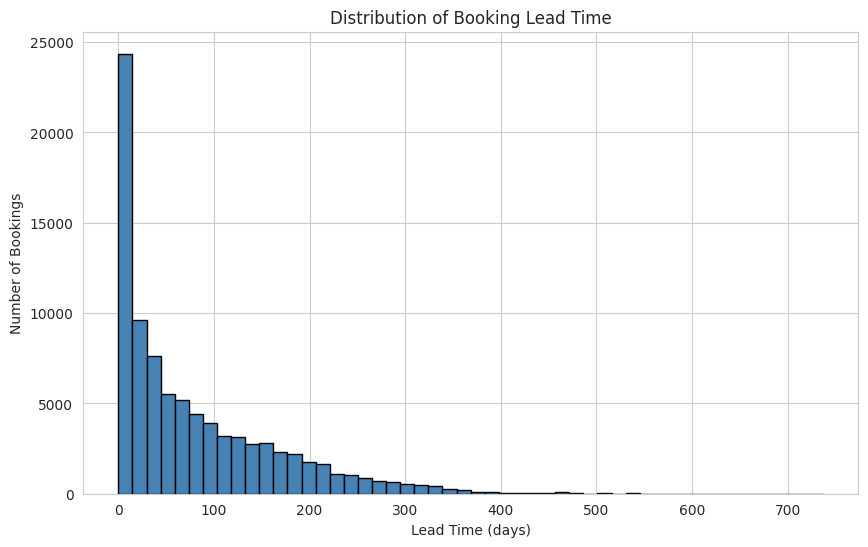

In [68]:
plt.figure(figsize=(10,6))
plt.hist(df["lead_time"], bins=50, color="steelblue", edgecolor="black")
plt.title("Distribution of Booking Lead Time")
plt.xlabel("Lead Time (days)")
plt.ylabel("Number of Bookings")
plt.savefig("images/visualization_01.png", dpi=150, bbox_inches="tight")
plt.show()

Histogram (lead time): Heavily right-skewed. About 24,000 bookings were made within roughly 0-15 days of arrival, and the count falls steadily after that. Most guests book late, but a small group books 300+ days ahead, which is why the mean is far above the median.

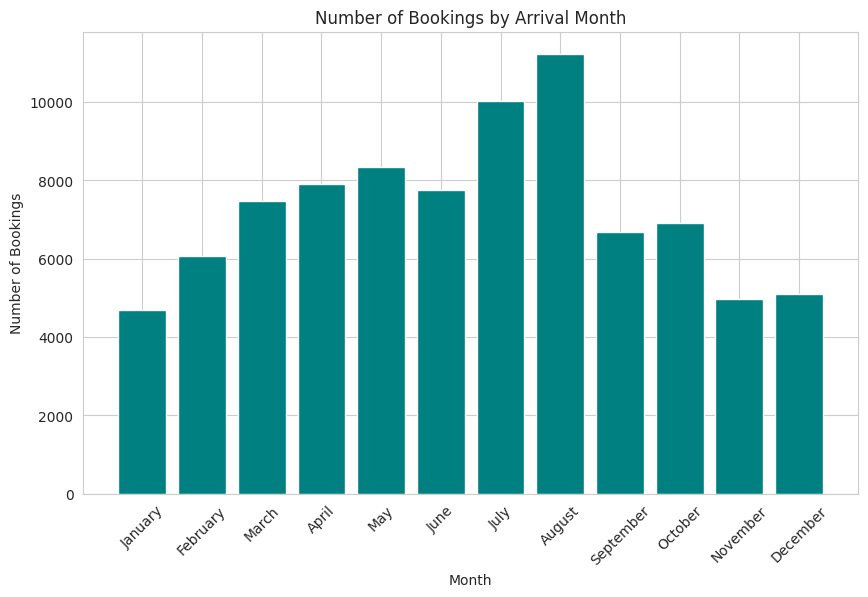

In [69]:
monthly = df["arrival_month"].value_counts().reindex(month_order)
plt.figure(figsize=(10,6))
plt.bar(monthly.index, monthly.values, color="teal")
plt.title("Number of Bookings by Arrival Month")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.savefig("images/visualization_02.png", dpi=150, bbox_inches="tight")
plt.show()

Bar chart (bookings by month): August is the busiest month (about 11,000 bookings), followed by July (about 10,000). January is the lowest (about 4,700). Demand peaks in summer

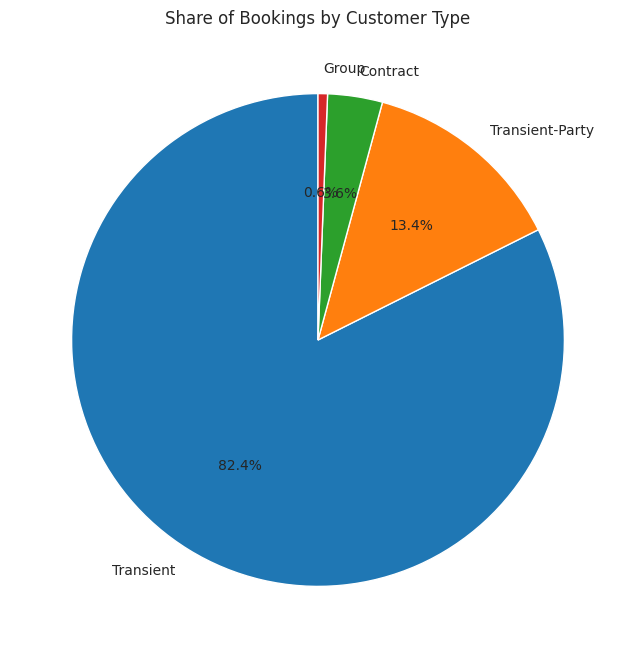

In [70]:
seg = df["customer_type"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(seg.values, labels=seg.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Bookings by Customer Type")
plt.savefig("images/visualization_03.png", dpi=150, bbox_inches="tight")
plt.show()

Pie chart (customer type): Transient customers make up 82.4% of bookings and Transient-Party 13.4%. Contract and Group together are under 5%. The hotels depend mainly on individual travelers, not group or contract business.

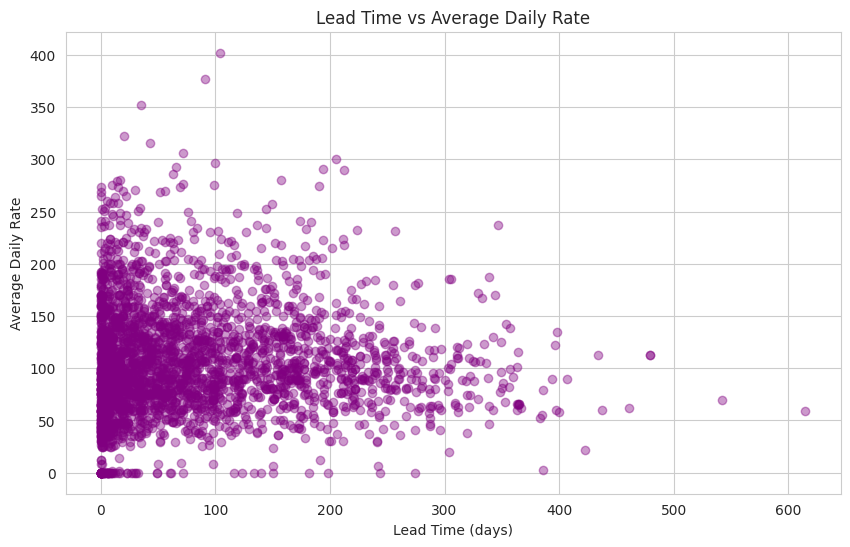

In [71]:
s = df[df.average_daily_rate < 500].sample(3000, random_state=42)
plt.figure(figsize=(10,6))
plt.scatter(s["lead_time"], s["average_daily_rate"], alpha=0.4, color="purple")
plt.title("Lead Time vs Average Daily Rate")
plt.xlabel("Lead Time (days)")
plt.ylabel("Average Daily Rate")
plt.savefig("images/visualization_04.png", dpi=150, bbox_inches="tight")
plt.show()

Scatter plot (lead time vs rate): The points form a wide cloud with no clear trend. Booking earlier does not mean paying more or less, which matches the correlation of about 0.02.

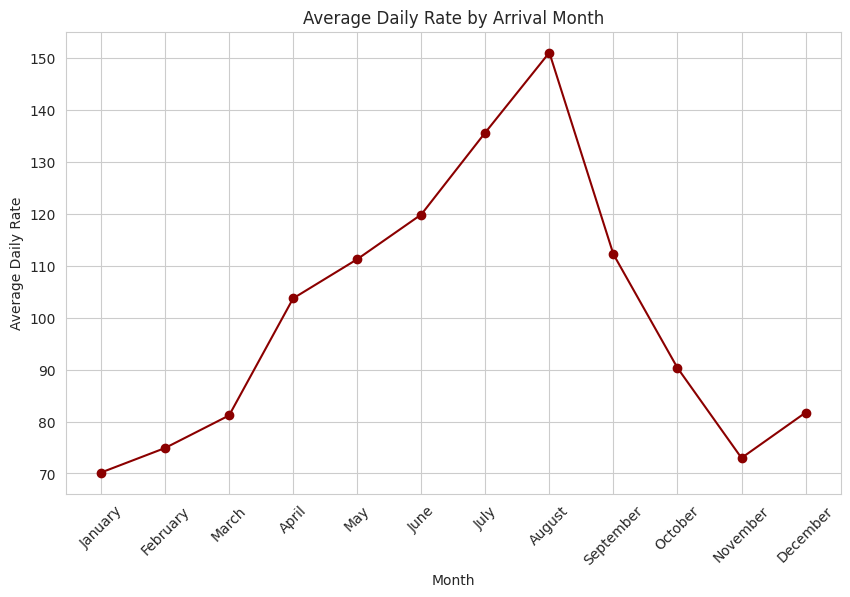

In [72]:
adr_month = df[df.average_daily_rate < 500].groupby("arrival_month")["average_daily_rate"].mean().reindex(month_order)
plt.figure(figsize=(10,6))
plt.plot(adr_month.index, adr_month.values, marker="o", color="darkred")
plt.title("Average Daily Rate by Arrival Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Rate")
plt.xticks(rotation=45)
plt.savefig("images/visualization_05.png", dpi=150, bbox_inches="tight")
plt.show()

Line chart (rate by month): The average rate rises from about 70 in January to a peak of about 150 in August, then drops sharply to about 73 in November. Price follows demand, and the busiest month is also the most expensive.

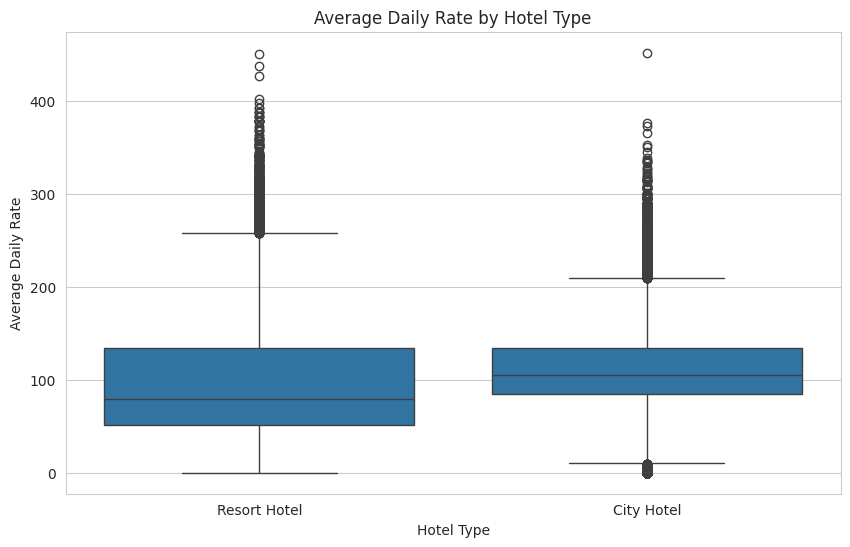

In [73]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[df.average_daily_rate < 500], x="hotel", y="average_daily_rate")
plt.title("Average Daily Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate")
plt.savefig("images/visualization_06.png", dpi=150, bbox_inches="tight")
plt.show()

Box plot (rate by hotel): City Hotel has a slightly higher median rate (about 105) than Resort Hotel (about 80). The Resort Hotel has a wider spread and more high-price outliers (up to about 450), likely from peak-season rates.

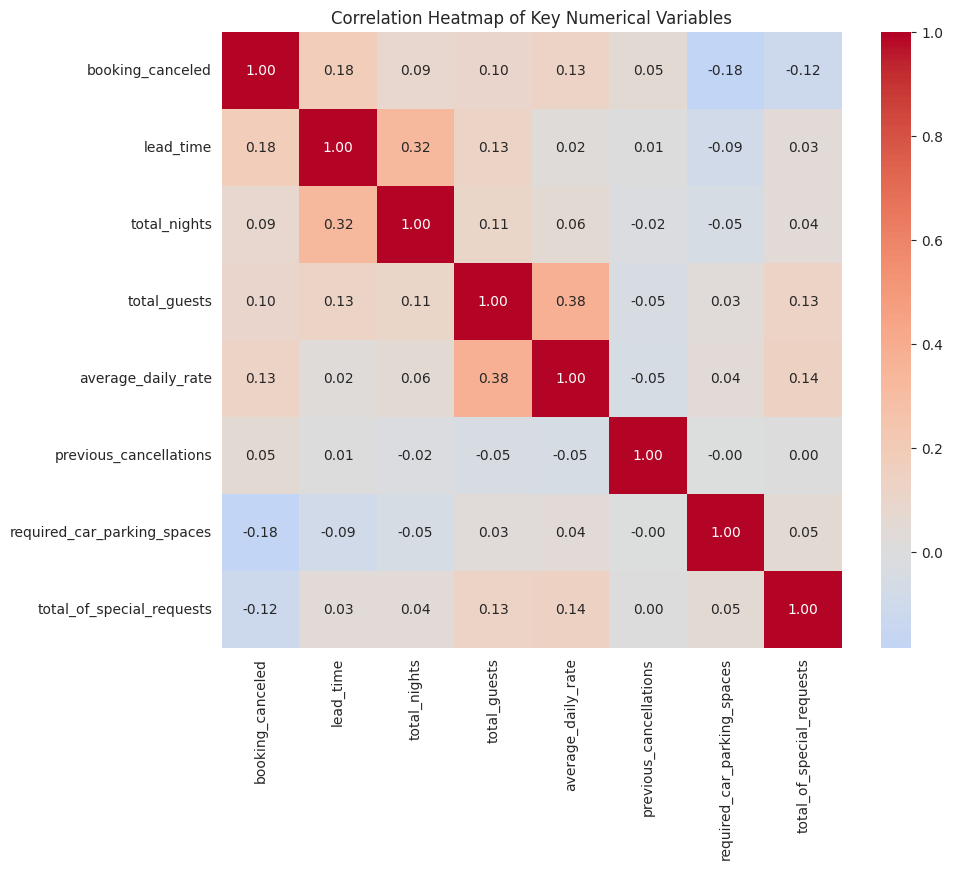

In [74]:
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Key Numerical Variables")
plt.savefig("images/visualization_07.png", dpi=150, bbox_inches="tight")
plt.show()

Heatmap: The strongest correlations with cancellation are lead time (+0.18) and parking spaces (-0.18). The strongest link between two other variables is total guests and daily rate (+0.38), then lead time and total nights (+0.32). All are weak to moderate.

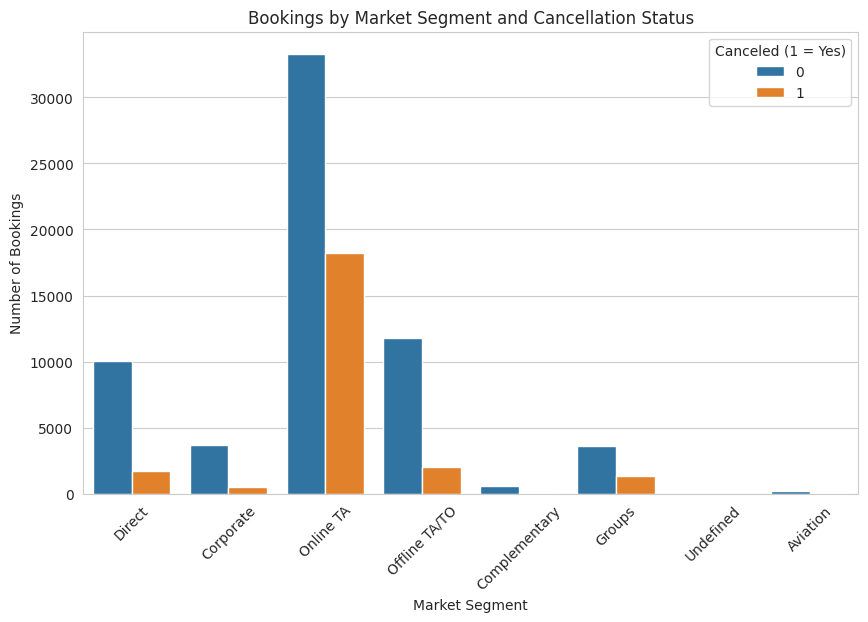

In [75]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x="market_segment", hue="booking_canceled")
plt.title("Bookings by Market Segment and Cancellation Status")
plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.legend(title="Canceled (1 = Yes)")
plt.savefig("images/visualization_08.png", dpi=150, bbox_inches="tight")
plt.show()

Count plot (market segment): Online TA has by far the most bookings (about 33,000 kept vs 18,000 canceled), so it also has the highest cancellation rate. Corporate and Direct bookings are mostly kept.

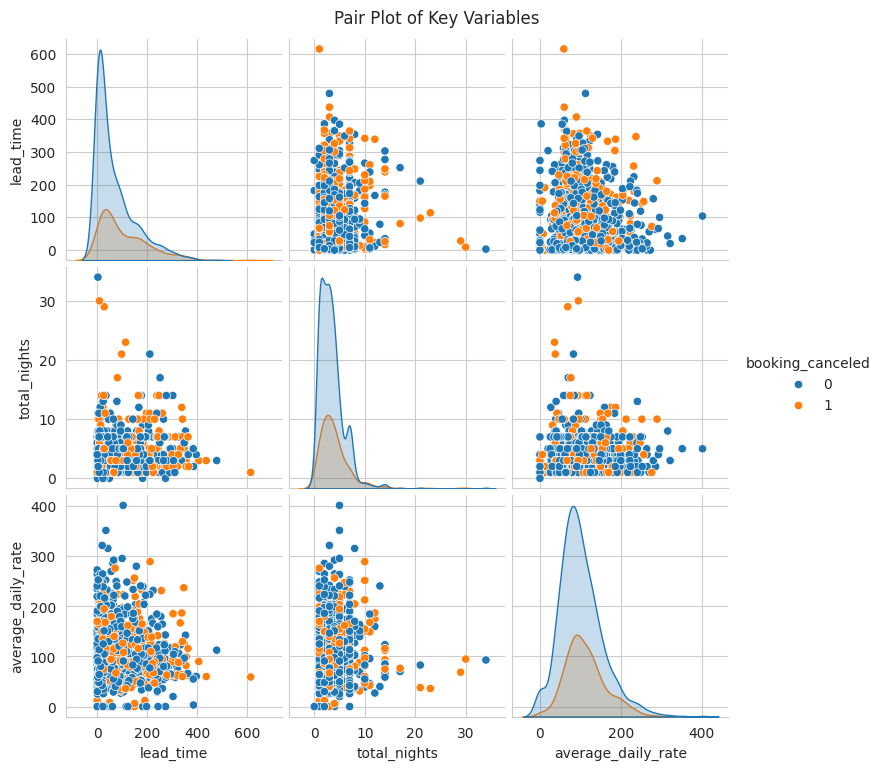

In [76]:
pp = df[df.average_daily_rate < 500][["lead_time", "total_nights", "average_daily_rate", "booking_canceled"]].sample(1500, random_state=42)
g = sns.pairplot(pp, hue="booking_canceled", height=2.5)
g.fig.suptitle("Pair Plot of Key Variables", y=1.02)
g.savefig("images/visualization_09.png", dpi=150, bbox_inches="tight")
plt.show()

Pair plot: Canceled bookings (orange) are spread toward longer lead times, while non-canceled bookings (blue) cluster near zero lead time. Total nights and daily rate show no strong separation.

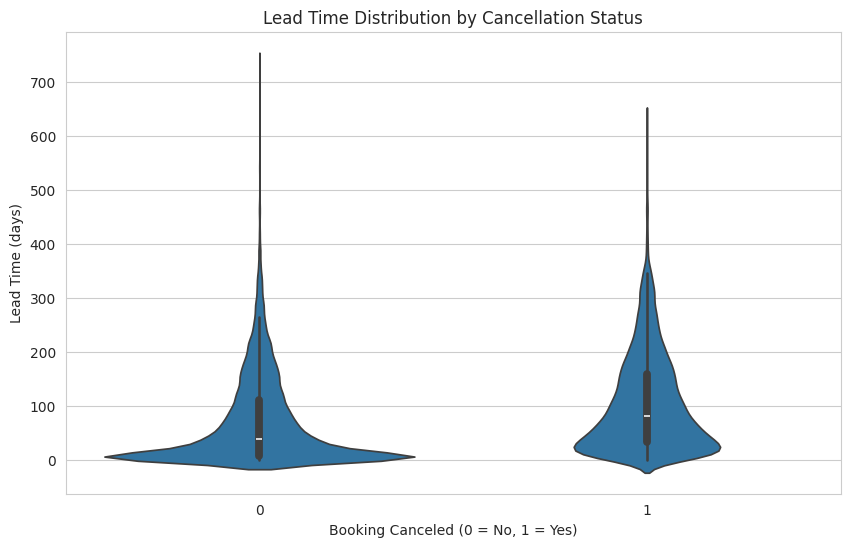

In [77]:
plt.figure(figsize=(10,6))
sns.violinplot(data=df, x="booking_canceled", y="lead_time")
plt.title("Lead Time Distribution by Cancellation Status")
plt.xlabel("Booking Canceled (0 = No, 1 = Yes)")
plt.ylabel("Lead Time (days)")
plt.savefig("images/visualization_10.png", dpi=150, bbox_inches="tight")
plt.show()

Violin plot: The non-canceled group is concentrated at very short lead times. The canceled group is wider, with a median of about 80 days compared to about 40, confirming that longer lead time goes with more cancellations.

In [78]:
print("Cancel rate by hotel (%):")
print((df.groupby("hotel")["booking_canceled"].mean()*100).round(1))
print("\nBusiest months:")
print(df["arrival_month"].value_counts().head(3))
print("\nAvg daily rate by month (rate < 500):")
print(df[df.average_daily_rate<500].groupby("arrival_month")["average_daily_rate"].mean().round(1).sort_values(ascending=False).head(3))
print("\nCancel rate by market segment (%):")
print((df.groupby("market_segment")["booking_canceled"].mean()*100).round(1).sort_values(ascending=False))

Cancel rate by hotel (%):
hotel
City Hotel      30.1
Resort Hotel    23.5
Name: booking_canceled, dtype: float64

Busiest months:
arrival_month
August    11242
July      10041
May        8343
Name: count, dtype: int64

Avg daily rate by month (rate < 500):
arrival_month
August    151.1
July      135.7
June      119.9
Name: average_daily_rate, dtype: float64

Cancel rate by market segment (%):
market_segment
Undefined        100.0
Online TA         35.4
Groups            27.1
Aviation          19.9
Direct            14.8
Offline TA/TO     14.8
Complementary     12.3
Corporate         12.1
Name: booking_canceled, dtype: float64


In [79]:
!zip -r project_files.zip images hotel_bookings.csv
from google.colab import files
files.download("project_files.zip")

updating: images/ (stored 0%)
updating: images/visualization_10.png (deflated 13%)
updating: images/visualization_06.png (deflated 21%)
updating: images/visualization_09.png (deflated 2%)
updating: images/visualization_02.png (deflated 19%)
updating: images/visualization_07.png (deflated 12%)
updating: images/visualization_01.png (deflated 25%)
updating: images/visualization_05.png (deflated 12%)
updating: images/visualization_04.png (deflated 4%)
updating: images/visualization_08.png (deflated 20%)
updating: images/visualization_03.png (deflated 8%)
updating: hotel_bookings.csv (deflated 92%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [80]:
df.to_csv("cleaned_hotel_bookings.csv", index=False)
from google.colab import files
files.download("cleaned_hotel_bookings.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
print((df.groupby("hotel")["booking_canceled"].mean()*100).round(1))

hotel
City Hotel      30.1
Resort Hotel    23.5
Name: booking_canceled, dtype: float64
